# LAB — Vision-Language Models: CLIP & LLaVA

**Full Name:** Loubna El ghazi 

**Environment:** Kaggle   
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

Plan: 
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?

CLIP (Contrastive Language–Image Pre-training) is a vision-language model developed by OpenAI. It learns to associate images with their corresponding textual descriptions by comparing image and text representations in a shared embedding space.

**Q2.** What are its two main components?  

CLIP has two main components: an image encoder, which extracts visual features from images, and a text encoder, which extracts semantic features from text.

**Q3.** What is the role of `CLIPProcessor`?  

CLIPProcessor prepares input data for the model. It preprocesses images and tokenizes text, converting them into tensors in the format expected by CLIP.


**Q4.** What is the role of `CLIPModel`?

CLIPModel contains the pretrained image and text encoders. It generates image and text representations and can calculate image-text similarity scores.

In [1]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [2]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  

The image size is expressed as a tuple containing its width and height in pixels. It can be obtained using image.size. The exact dimensions depend on the uploaded image (in our case is ,**the image size is 1280 × 960 pixels** (width × height).).

**Q6.** What type of data is stored in the PIL image object?

The PIL image object stores pixel data representing the image. In this case, the image is in **RGB mode**, meaning that each pixel is represented by three color channels: Red, Green, and Blue. The image has a resolution of 1280 × 960 pixels.

Image size: (1280, 960)
Image mode: RGB
<class 'PIL.Image.Image'>


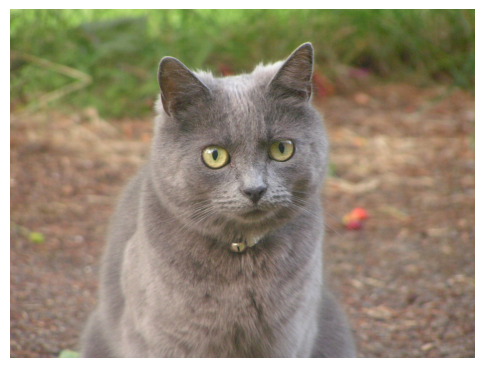

In [3]:
# Upload an image in yur environnement and change the filename if necessary.
IMAGE_PATH = "/kaggle/input/datasets/loubnaelghazi/data-clip/Greycat.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)
print(type(image))
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  

The description **"a photo of a cat"** has the highest probability, with a score of **0.9884 (98.84%)**.


**Q8.** Is it compatible with the actual image?  

Yes, it is compatible with the actual image because the image contains a cat, and CLIP assigns the highest probability to the description "a photo of a cat".


**Q9.** Why can CLIP compare an image with a sentence?  

CLIP can compare an image with a sentence because it uses two encoders: an image encoder and a text encoder. Both convert images and text into a shared embedding space, where their similarity can be measured. Matching image-text pairs receive higher similarity scores.


**Q10.** What does `softmax()` do?

The softmax() function converts the model's similarity scores into probabilities that sum to 1 across the candidate descriptions. Higher probabilities indicate descriptions that are more compatible with the image.

In [4]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9884
a photo of a dog                   : 0.0042
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0005
a photo of a person                : 0.0068


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  

Zero-shot classification is the task of classifying an image into one of several candidate classes without training a new classifier specifically for those classes.

**Q12.** Why is it not necessary to train a new classifier?  

because CLIP has already been pretrained on image-text pairs. It can compare an image with text descriptions and select the most similar one.


**Q13.** What happens if the correct class is not included in the candidate classes?

CLIP will select the most compatible class among the available options, even if that prediction is incorrect. So, the result depends on the candidate classes provided.

In [5]:


def classify_image(image, classes):
    
    texts = []

    for cls in classes:
        texts.append("a photo of a " + cls)
        
    # Prepare the image and text inputs
    inputs = processor(
        text=texts,images=image,
        return_tensors="pt",
        padding=True )

    for k in inputs:
        inputs[k] = inputs[k].to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    probs = outputs.logits_per_image.softmax(dim=1)[0]
    
    # Find the class with the highest probability
    
    best_idx = probs.argmax().item()

    return classes[best_idx], probs[best_idx].item()

    
classes = ["cat", "dog", "car", "airplane", "horse", "bird"]


prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.993224561214447


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  

The obtained accuracy is 100%. CLIP correctly classified all 10 images in the dataset (10 out of 10 images).


**Q15.** Which images are incorrectly classified?  

No images were incorrectly classified. All 10 images were assigned to their correct classes: cat, dog, car, airplane, or horse.


**Q16.** Give at least two possible reasons for the errors.
Although no classification errors occurred in this experiment, possible reasons for errors include:

Visual similarities between classes: Some objects may share similar visual characteristics, making them difficult to distinguish.

Complex backgrounds: Backgrounds, poor lighting, or unusual viewing angles may affect the model's predictions.

Ambiguous images: An image may contain multiple objects or may not clearly show the main object.

Candidate class descriptions: CLIP selects the most compatible class among the provided candidates. If the correct class is missing, it may produce an incorrect prediction.




In [6]:



IMAGE_DIR = "/kaggle/input/datasets/loubnaelghazi/data-clip/"

dataset = [
    ("18_Year_Old_Windsprite.jpg", "dog"),
    ("Airliners_28.07.2009_10-01-28.JPG", "airplane"),
    ("Airplanes_cross_path_2409-1639.jpg", "airplane"),
    ("Birma_seal_u_tortie_point.jpg", "cat"),
    ("Exotic_Rides_W70_in_Asphalt_9_Legends.webp", "car"),
    ("Greycat.jpg", "cat"),
    ("Mercedes-Benz_GLC_300_Coupe_(C253)_Facelift_in_Black.jpg", "car"),
    ("_Louie_the_Italian_Greyhound_.jpg", "dog"),
    ("cheval.jpg", "horse"),
    ("horse.jpg", "horse")
]

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

correct = 0

for filename, actual_class in dataset:
    
    image_test = Image.open(IMAGE_DIR + filename).convert("RGB")
    prediction, probability = classify_image(image_test, classes)

    print(filename, "| Actual:", actual_class,
          "| Predicted:", prediction,
          "| Probability:", round(probability, 4),
          "| Correct:", prediction == actual_class)

    if prediction == actual_class:
        correct = correct + 1

accuracy = correct / len(dataset) * 100
print("Accuracy:", round(accuracy, 2), "%")


18_Year_Old_Windsprite.jpg | Actual: dog | Predicted: dog | Probability: 0.9752 | Correct: True
Airliners_28.07.2009_10-01-28.JPG | Actual: airplane | Predicted: airplane | Probability: 0.9808 | Correct: True
Airplanes_cross_path_2409-1639.jpg | Actual: airplane | Predicted: airplane | Probability: 0.9951 | Correct: True
Birma_seal_u_tortie_point.jpg | Actual: cat | Predicted: cat | Probability: 0.995 | Correct: True
Exotic_Rides_W70_in_Asphalt_9_Legends.webp | Actual: car | Predicted: car | Probability: 0.987 | Correct: True
Greycat.jpg | Actual: cat | Predicted: cat | Probability: 0.9932 | Correct: True
Mercedes-Benz_GLC_300_Coupe_(C253)_Facelift_in_Black.jpg | Actual: car | Predicted: car | Probability: 0.9952 | Correct: True
_Louie_the_Italian_Greyhound_.jpg | Actual: dog | Predicted: dog | Probability: 0.9779 | Correct: True
cheval.jpg | Actual: horse | Predicted: horse | Probability: 0.9992 | Correct: True
horse.jpg | Actual: horse | Predicted: horse | Probability: 0.9997 | Corre

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  

No, the scores are not identical. They vary depending on the wording of each prompt. For example, "a cat" has a score of 0.0121, while "a photograph showing a cat" has a score of 0.806.


**Q18.** Which prompt gives the highest score?  

The prompt "a photograph showing a cat" gives the highest score, with a probability of 0.806 (80.6%).


**Q19.** What does this demonstrate about prompt formulation?

This demonstrates that prompt formulation influences CLIP's similarity scores. Even when different prompts describe the same object, their wording can produce different results. In this experiment, "a photograph showing a cat" matches the image-text representation better than the other prompts. Therefore, prompt selection can affect CLIP's performance in zero-shot classification.

In [7]:

prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True)

for k in inputs:
    inputs[k] = inputs[k].to(device)

with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0]

probabilities = scores.softmax(dim=0)

for i in range(len(prompts)):
    print(prompts[i], ":", round(probabilities[i].item(), 4))

a cat : 0.0121
a photo of a cat : 0.078
a photograph showing a cat : 0.8046
an image containing a cat : 0.0258
a domestic animal called a cat : 0.0795


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?

The most similar image is 18_Year_Old_Windsprite.jpg, with a similarity score of 0.2483.


**Q21.** Is it semantically relevant?  

No, the retrieved images are not clearly relevant to the query “a person playing football”. The dataset may not contain an image that matches this specific scene. CLIP still returns the five most similar images, even when none is a good match.


**Q22.** Why does this method not require image labels?  

We do not need image labels because CLIP compares the text embedding with the image embeddings in a shared feature space. It can retrieve images based on their semantic similarity to the text query without requiring manually assigned labels.


**Q23.** Give one real-world application of semantic image retrieval.

A real-world application is searching for images in a large database using natural language. For example, a user could type “a person playing football” to find relevant images without manually browsing or labeling every image.

Number of images: 20
Query: a person playing football
18_Year_Old_Windsprite.jpg | Similarity: 0.2484
Dasht1.jpg | Similarity: 0.2224
bird1.jpg | Similarity: 0.2037
Greycat.jpg | Similarity: 0.2019
horse.jpg | Similarity: 0.1997


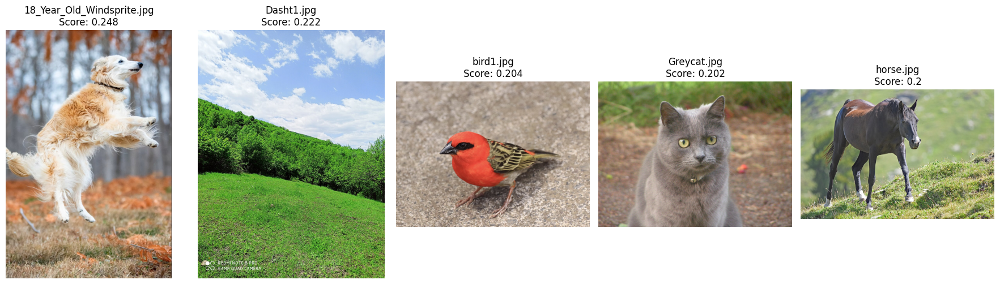

In [8]:
import os
import matplotlib.pyplot as plt


QUERY = "a person playing football"

image_names = []
embeddings = []

# 1. Calculate image embeddings

for filename in os.listdir(IMAGE_DIR):

    if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):

        image_path = os.path.join(IMAGE_DIR, filename)
        image_test = Image.open(image_path).convert("RGB")

        inputs = processor(images=image_test, return_tensors="pt")

        for k in inputs:
            inputs[k] = inputs[k].to(device)

        with torch.no_grad():
            image_features = model.get_image_features(**inputs)

        if not isinstance(image_features, torch.Tensor):
            image_features = image_features.pooler_output

        image_features = image_features / image_features.norm(
            dim=-1, keepdim=True )

        embeddings.append(image_features[0].cpu())
        image_names.append(filename)

print("Number of images:", len(image_names))

# 2. Calculate the text embedding
text_inputs = processor(
    text=[QUERY],
    return_tensors="pt",
    padding=True)

for k in text_inputs:
    text_inputs[k] = text_inputs[k].to(device)

with torch.no_grad():
    text_features = model.get_text_features(**text_inputs)

if not isinstance(text_features, torch.Tensor):
    text_features = text_features.pooler_output

text_features = text_features / text_features.norm(
    dim=-1, keepdim=True)

text_features = text_features[0].cpu()



# 3. Calculate cosine similarity

image_embeddings = torch.stack(embeddings)
similarities = image_embeddings @ text_features

# 4. Display the Top-5 results

top_results = torch.topk(similarities, k=min(5, len(image_names)))

print("Query:", QUERY)

for i in range(len(top_results.indices)):
    index = top_results.indices[i].item()
    score = top_results.values[i].item()
    print(image_names[index], "| Similarity:", round(score, 4))

# 5. Display the images
fig, axes = plt.subplots(1, len(top_results.indices), figsize=(18, 5))

if len(top_results.indices) == 1:
    axes = [axes]

for i in range(len(top_results.indices)):
    index = top_results.indices[i].item()
    image_path = os.path.join(IMAGE_DIR, image_names[index])
    image_test = Image.open(image_path).convert("RGB")

    axes[i].imshow(image_test)
    axes[i].set_title(
        image_names[index] + "\nScore: " +
        str(round(top_results.values[i].item(), 3)))
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Part C — LLaVA

## Exercise 9 — Architecture


```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
PROJECTION LAYER
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  

The vision encoder extracts visual features from the image and converts them into numerical representations that capture information about its content.


**Q25.** Why is a projection layer required?  

The projection layer maps the visual features into a representation compatible with the language model's input space, allowing the model to use visual information when generating a response.


**Q26.** What is the role of the language model?

The language model processes the visual information together with the user's question and generates a relevant response in natural language.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
3. How many people are visible?
4. What objects can you identify?
5. Describe the image in detail.

Record the answers.

In [9]:
import torch

print("Number of GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(torch.cuda.get_device_name(i))

Number of GPUs: 2
Tesla T4
Tesla T4


In [ ]:
#%pip uninstall -y transformers tokenizers
#%pip install "transformers==4.51.3" "tokenizers==0.21.1"

In [11]:
import transformers
import sys

print("Python:", sys.version)
print("Transformers:", transformers.__version__)
print("Transformers path:", transformers.__file__)

import transformers.processing_utils as pu
print("Function available:", hasattr(pu, "_validate_images_text_input_order"))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Transformers: 4.51.3
Transformers path: /usr/local/lib/python3.13/dist-packages/transformers/__init__.py
Function available: True


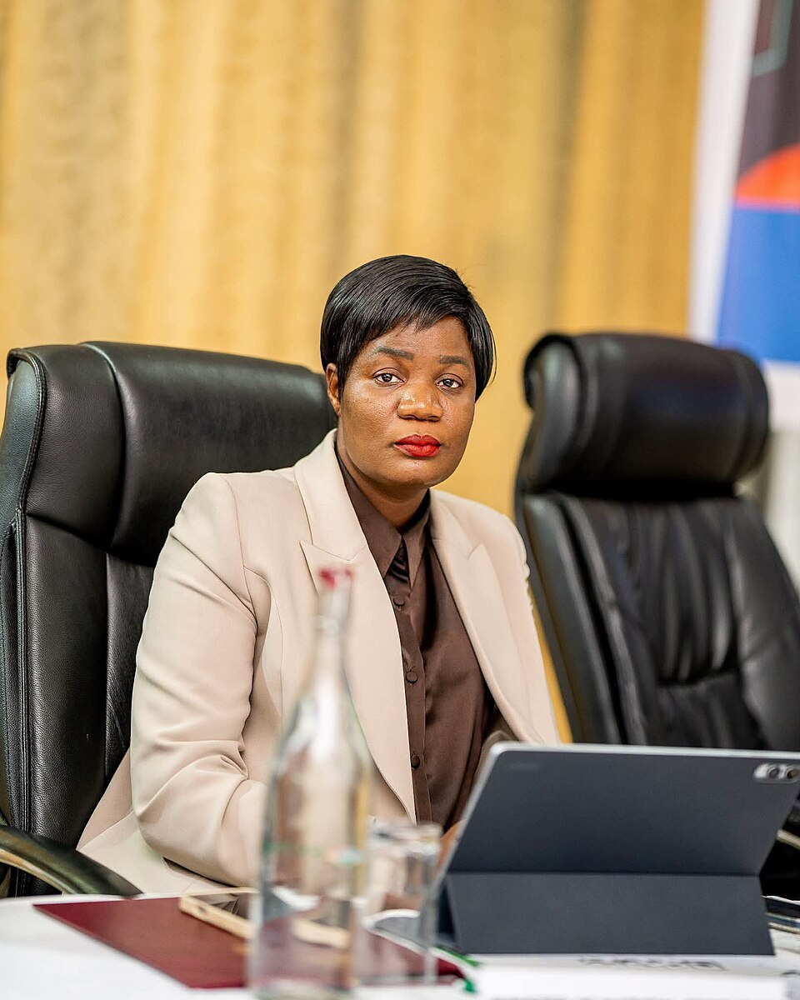

In [16]:
image = Image.open(os.path.join(IMAGE_DIR, "human.jpg")).convert("RGB")
display(image)

In [14]:
# LLaVA reference implementation.
# NOTE: This model is much heavier than CLIP. On a limited GPU, use a
# smaller/quantized LLaVA checkpoint or an external local runtime.
#
# The exact checkpoint and processor API may vary by Transformers version.
# Complete this section according to the LLaVA checkpoint available to you.

import torch
from transformers import AutoProcessor, LlavaForConditionalGeneration

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True)

print("LLaVA loaded successfully!")

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

LLaVA loaded successfully!


In [18]:
questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

for question in questions:
    prompt = "USER: <image>\n" + question + "\nASSISTANT:"

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    )

    inputs = inputs.to("cuda", dtype=torch.float16)

    with torch.no_grad():
        output = llava.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    answer = processor_llava.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    print("\nQuestion:", question)
    print("Answer:", answer)


Question: What is happening in this image?
Answer: In the image, a woman is sitting in a chair, working on a laptop. She is wearing a suit and appears to be focused on her task. The scene takes place in a room with a dining table nearby. There are also two bottles in the room, one closer to the woman and the other further away. The overall atmosphere suggests a professional setting where the woman is engaged in her work.

Question: How many people are visible?
Answer: There is only one person visible in the image, a woman sitting in a chair.

Question: What objects can you identify?
Answer: In the image, you can identify a woman sitting in a chair, a bottle, a laptop, and a cell phone. The woman is wearing a suit and appears to be working or engaged in a task. The bottle is placed on a table, and the laptop and cell phone are also on the table, suggesting that she might be using them for work or personal purposes.

Question: Describe the image in detail.
Answer: The image features a w

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  

The obtained VQA accuracy is 84%. Out of 25 questions, 21 answers were evaluated as correct and 4 as incorrect. The accuracy was calculated by dividing the number of correct answers by the total number of questions and multiplying by 100.


**Q28.** Which types of questions are difficult for LLaVA?

LLaVA had difficulties with questions about the location and visibility of people or animals. For example, it sometimes stated that people or animals were not visible even when parts of them could be seen in the image. The model could also provide inconsistent answers or include details that were not clearly supported by the image. These results show that human evaluation is important for verifying the reliability of visual question answering


In [20]:


images_to_test = [
    "human.jpg",
    "Greycat.jpg",
    "18_Year_Old_Windsprite.jpg",
    "cheval.jpg",
    "food.jpg"
]

questions = [
    "How many people are visible?",
    "What objects can you see?",
    "Where are the people or animals?",
    "What are they doing?",
    "Describe the image in detail."
]

results = []

for filename in images_to_test:
    image_path = os.path.join(IMAGE_DIR, filename)
    current_image = Image.open(image_path).convert("RGB")

    for question in questions:
        prompt = "USER: <image>\n" + question + "\nASSISTANT:"

        inputs = processor_llava(
            text=prompt,
            images=current_image,
            return_tensors="pt"
        )

        inputs = inputs.to("cuda", dtype=torch.float16)

        with torch.no_grad():
            output = llava.generate(
                **inputs,
                max_new_tokens=120,
                do_sample=False
            )

        answer = processor_llava.decode(
            output[0][inputs["input_ids"].shape[1]:],
            skip_special_tokens=True
        ).strip()

        results.append({
            "Image": filename,
            "Question": question,
            "LLaVA Answer": answer,
            "Human Evaluation": ""
        })

df = pd.DataFrame(results)


pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

display(df)


,Image,Question,LLaVA Answer,Human Evaluation
0,human.jpg,How many people are visible?,"There is only one person visible in the image, a woman sitting in a chair.",
1,human.jpg,What objects can you see?,"In the image, you can see a woman sitting in a chair, a laptop, a bottle, and a vase. The woman is wearing a suit and appears to be working or engaged in a task. The laptop is placed on a table in front of her, and the bottle and vase are also on the table.",
2,human.jpg,Where are the people or animals?,The people or animals are not visible in the image. The focus is on the woman sitting in the chair and the laptop she is using.,
3,human.jpg,What are they doing?,"The woman is sitting in a chair, working on a laptop. She appears to be focused on her task, possibly in a professional setting.",
4,human.jpg,Describe the image in detail.,"The image features a woman sitting in a chair, wearing a suit and tie. She is looking at a laptop placed on a table in front of her. The woman appears to be focused on her work or task at hand.\n\nThere are two chairs in the scene, one occupied by the woman and another one located further back. A bottle can be seen on the table, possibly containing a beverage or a work-related item. The overall setting suggests a professional environment.",
5,Greycat.jpg,How many people are visible?,0,
6,Greycat.jpg,What objects can you see?,"In the image, you can see a cat sitting on the ground, a dirt ground, and a few red berries scattered around the area.",
7,Greycat.jpg,Where are the people or animals?,"The cat is sitting on the ground, and there are no people or animals visible in the image.",
8,Greycat.jpg,What are they doing?,"The cat is sitting on the ground, looking at the camera.",
9,Greycat.jpg,Describe the image in detail.,"The image features a gray cat sitting on the ground, looking directly at the camera. The cat appears to be staring at the viewer, possibly curious or interested in the person taking the photo. The cat is positioned in the center of the image, with its body facing the camera.",


In [23]:

evaluations = [
    "Correct",    # 0 - human.jpg: number of people
    "Correct",    # 1 - human.jpg: objects 
    "Incorrect",  # 2 - human.jpg: says people are not visible
    "Correct",    # 3 - human.jpg: what the woman is doing
    "Correct",    # 4 - human.jpg: detailed description 

    "Correct",    # 5 - Greycat.jpg: number of people
    "Correct",    # 6 - Greycat.jpg: objects 
    "Correct",    # 7 - Greycat.jpg: location
    "Correct",    # 8 - Greycat.jpg: activity
    "Correct",    # 9 - Greycat.jpg: detailed description

    "Correct",    # 10 - dog image: number of people
    "Correct",    # 11 - dog image: object
    "Incorrect",  # 12 - dog image: says animals are not visible
    "Correct",    # 13 - dog image: activity
    "Correct",    # 14 - dog image: detailed description 

    "Correct",    # 15 - cheval.jpg: number of people
    "Correct",    # 16 - cheval.jpg: objects 
    "Correct",    # 17 - cheval.jpg: location
    "Correct",    # 18 - cheval.jpg: activity 
    "Correct",    # 19 - cheval.jpg: detailed description

    "Incorrect",    # 20 - food.jpg: 
    "Correct",    # 21 - food.jpg: food and objects 
    "Correct",  # 22 - food.jpg: potentially contradicts visible people
    "Correct",    # 23 - food.jpg: eating together 
    "Incorrect"   # 24 - food.jpg: description is cut off
]

df["Human Evaluation"] = evaluations

display(df)


,Image,Question,LLaVA Answer,Human Evaluation
0,human.jpg,How many people are visible?,"There is only one person visible in the image, a woman sitting in a chair.",Correct
1,human.jpg,What objects can you see?,"In the image, you can see a woman sitting in a chair, a laptop, a bottle, and a vase. The woman is wearing a suit and appears to be working or engaged in a task. The laptop is placed on a table in front of her, and the bottle and vase are also on the table.",Correct
2,human.jpg,Where are the people or animals?,The people or animals are not visible in the image. The focus is on the woman sitting in the chair and the laptop she is using.,Incorrect
3,human.jpg,What are they doing?,"The woman is sitting in a chair, working on a laptop. She appears to be focused on her task, possibly in a professional setting.",Correct
4,human.jpg,Describe the image in detail.,"The image features a woman sitting in a chair, wearing a suit and tie. She is looking at a laptop placed on a table in front of her. The woman appears to be focused on her work or task at hand.\n\nThere are two chairs in the scene, one occupied by the woman and another one located further back. A bottle can be seen on the table, possibly containing a beverage or a work-related item. The overall setting suggests a professional environment.",Correct
5,Greycat.jpg,How many people are visible?,0,Correct
6,Greycat.jpg,What objects can you see?,"In the image, you can see a cat sitting on the ground, a dirt ground, and a few red berries scattered around the area.",Correct
7,Greycat.jpg,Where are the people or animals?,"The cat is sitting on the ground, and there are no people or animals visible in the image.",Correct
8,Greycat.jpg,What are they doing?,"The cat is sitting on the ground, looking at the camera.",Correct
9,Greycat.jpg,Describe the image in detail.,"The image features a gray cat sitting on the ground, looking directly at the camera. The cat appears to be staring at the viewer, possibly curious or interested in the person taking the photo. The cat is positioned in the center of the image, with its body facing the camera.",Correct


In [24]:

correct = (df["Human Evaluation"] == "Correct").sum()
total = len(df)
accuracy = correct / total * 100

print(f"Correct answers: {correct}/{total}")
print(f"Incorrect answers: {(df['Human Evaluation'] == 'Incorrect').sum()}/{total}")
print(f"VQA Accuracy: {accuracy:.2f}%")


Correct answers: 21/25
Incorrect answers: 4/25
VQA Accuracy: 84.00%


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  

No, the bicycle does not exist in the image.


**Q30.** Did LLaVA invent information?  

Yes, LLaVA invented information. Although it correctly stated that there was no bicycle in the first answer, it later claimed that the bicycle was black and located on a hillside. These details are not supported by the image.

**Q31.** What is a visual hallucination?  

A visual hallucination occurs when a model generates information about an image that is incorrect or not supported by its visual content.

**Q32.** Why can a multimodal model hallucinate?

A multimodal model can hallucinate because it may rely on patterns learned during training rather than the actual image content. It may also be influenced by the wording of the question and generate a plausible answer even when the requested object is absent.

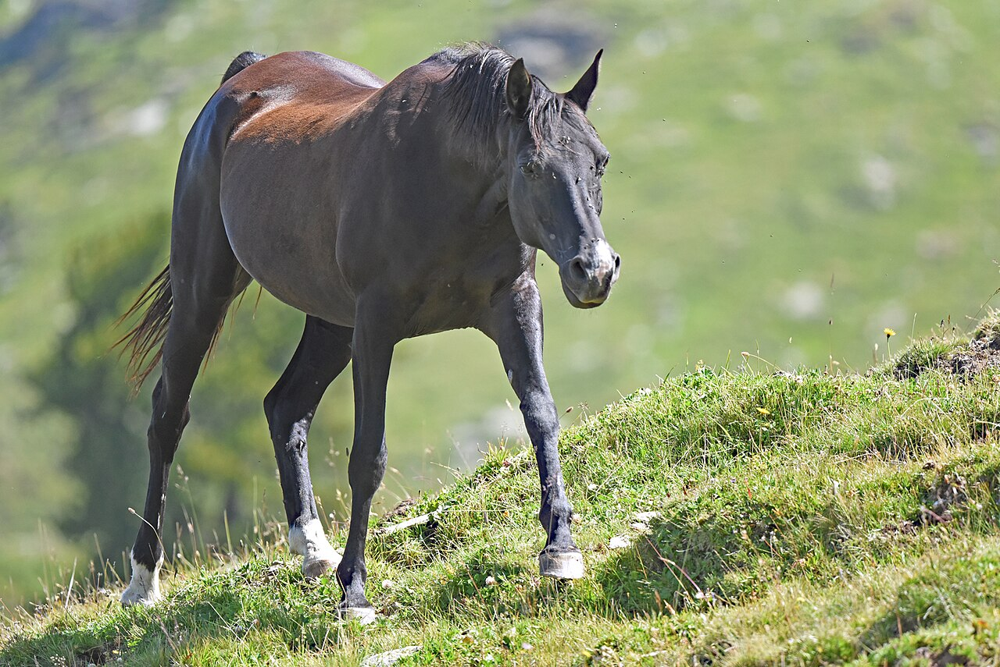

Question: Is there a bicycle in this image?
LLaVA Answer: No, there is no bicycle in this image. The image features a horse walking on a grassy hill.
------------------------------------------------------------
Question: What color is the bicycle?
LLaVA Answer: The bicycle is black.
------------------------------------------------------------
Question: Where is the bicycle located?
LLaVA Answer: The bicycle is located on a hillside, with the horse standing on the grass nearby.
------------------------------------------------------------


In [25]:


#  an image without a bicycle
filename = "horse.jpg"
image_path = os.path.join(IMAGE_DIR, filename)
image = Image.open(image_path).convert("RGB")

# Display the image to verify its content
display(image)

# Questions for the hallucination test
questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]


for question in questions:
    prompt = "USER: <image>\n" + question + "\nASSISTANT:"

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt")

    inputs = inputs.to("cuda", dtype=torch.float16)

    with torch.no_grad():
        output = llava.generate( **inputs,max_new_tokens=100,do_sample=False)

    answer = processor_llava.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    print("Question:", question)
    print("LLaVA Answer:", answer)
    print("-" * 60)


# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

| Property | CLIP | LLaVA |
|---|---|---|
| Input | Image and text descriptions | Image and text prompt/question |
| Main output | Image-text similarity scores | Generated text answer |
| Zero-shot classification | Yes | Yes, through prompting |
| Image retrieval | Yes | Not its main purpose |
| Text generation | No | Yes |
| VQA | Not directly | Yes |
| Open-ended response | No | Yes |

### Questions

**Q33.** Which model is better suited to image classification?  

CLIP is better suited to image classification because it compares an image with candidate text descriptions and selects the most similar one. In this experiment, CLIP correctly identified the horse with a score of 0.9998.


**Q34.** Which model is better for image description? 

LLaVA is better for image description because it generates natural-language descriptions. In this experiment, it identified the horse and described its appearance and surroundings.


**Q35.** Which model is better for visual question answering?  

LLaVA is better for visual question answering because it can answer questions about an image using natural language.


**Q36.** Explain the fundamental difference between CLIP and LLaVA.

CLIP learns a shared representation space for images and text, making it useful for classification and image retrieval. LLaVA combines a vision encoder with a language model to interpret images and generate text. So, CLIP mainly compares image-text similarity, while LLaVA supports image description and visual question answering.

In [27]:
# Candidate descriptions for CLIP
candidate_labels = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"]


clip_inputs = processor(
    text=candidate_labels,
    images=image,
    return_tensors="pt",
    padding=True)

clip_inputs = {
    key: value.to("cuda" if torch.cuda.is_available() else "cpu")
    for key, value in clip_inputs.items()}

with torch.no_grad():
    clip_outputs = model(**clip_inputs)


similarities = clip_outputs.logits_per_image[0]
probabilities = similarities.softmax(dim=0)

for label, score in zip(candidate_labels, probabilities.tolist()):
    print(f"{label}: {score:.4f}")

best_index = probabilities.argmax().item()
print("\nCLIP prediction:", candidate_labels[best_index])

a photo of a cat: 0.0001
a photo of a dog: 0.0002
a photo of a horse: 0.9998

CLIP prediction: a photo of a horse


In [28]:
#lava 

prompt = (
    "USER: <image>\n"
    "What animal is present in the image? "
    "Describe its appearance.\n"
    "ASSISTANT:"
)

llava_inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
)

llava_inputs = llava_inputs.to("cuda", dtype=torch.float16)

with torch.no_grad():
    llava_output = llava.generate(
        **llava_inputs,
        max_new_tokens=150,
        do_sample=False
    )

llava_answer = processor_llava.decode(
    llava_output[0][llava_inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
).strip()

print("LLaVA answer:")
print(llava_answer)


LLaVA answer:
A horse is present in the image. It is a large, dark brown horse with a black mane. The horse is walking on a grassy hillside, possibly in a field.


In [ ]:
# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [30]:
###MINI PROJET


image_extensions = (".jpg", ".jpeg", ".png", ".webp")

image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(image_extensions)
])

print("Number of images:", len(image_files))

clip_device = next(model.parameters()).device
model.eval()

image_embeddings = []
valid_image_files = []

for filename in image_files:
    image_path = os.path.join(IMAGE_DIR, filename)

    try:
        current_image = Image.open(image_path).convert("RGB")

        # Prepare image input for CLIP
        inputs = processor(
            images=current_image,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].to(clip_device)

       
        with torch.no_grad():
            embedding = model.get_image_features(
                pixel_values=pixel_values
            )

            # Handle different Transformers output formats
            if hasattr(embedding, "pooler_output"):
                embedding = embedding.pooler_output
            elif hasattr(embedding, "image_embeds"):
                embedding = embedding.image_embeds

            # Normalize the image embedding
            embedding = embedding / embedding.norm(
                dim=-1, keepdim=True
            )

        image_embeddings.append(embedding.squeeze(0).cpu())
        valid_image_files.append(filename)

    except Exception as error:
        print(f"Skipping {filename}: {error}")

if len(image_embeddings) == 0:
    raise RuntimeError(
        "No image embeddings were created. Check the CLIP model and processor." )

image_embeddings = torch.stack(image_embeddings)

print("Images indexed:", len(valid_image_files))
print("Embedding matrix shape:", image_embeddings.shape)
print("CLIP image database ready!")


Number of images: 20
Images indexed: 20
Embedding matrix shape: torch.Size([20, 512])
CLIP image database ready!


In [37]:

def multimodal_image_assistant(search_query, question, top_k=5):

 
    text_inputs = processor(
        text=[search_query],
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(clip_device)

    with torch.no_grad():
        text_embedding = model.get_text_features(
            input_ids=text_inputs["input_ids"],
            attention_mask=text_inputs.get("attention_mask")
        )

        # Handle different Transformers output formats
        if hasattr(text_embedding, "pooler_output"):
            text_embedding = text_embedding.pooler_output
        elif hasattr(text_embedding, "text_embeds"):
            text_embedding = text_embedding.text_embeds

        text_embedding = text_embedding / text_embedding.norm(
            dim=-1, keepdim=True
        )


    similarities = (
        image_embeddings.to(clip_device) @ text_embedding.T
    ).squeeze(1)

    k = min(top_k, len(valid_image_files))
    scores, indices = torch.topk(similarities, k=k)

    print("Search query:", search_query)
    print(f"Top {k} retrieved images")
    print("=" * 60)

    results = []

    # 3. Ask LLaVA to explain each retrieved image
    
    for rank, (score, index) in enumerate(
        zip(scores.tolist(), indices.tolist()), start=1
    ):
        filename = valid_image_files[index]
        image_path = os.path.join(IMAGE_DIR, filename)
        retrieved_image = Image.open(image_path).convert("RGB")

        print(f"\nRank: {rank}")
        print(f"Image: {filename}")
        print(f"CLIP similarity: {score:.4f}")
        display(retrieved_image)

        prompt = (
            "USER: <image>\n"
            + question
            + "\nAnswer based only on the visible image. "
              "If something is not visible, say so.\nASSISTANT:" )

        llava_inputs = processor_llava(text=prompt,images=retrieved_image,return_tensors="pt" ).to("cuda", dtype=torch.float16)

        with torch.no_grad():
            output = llava.generate(
                **llava_inputs,
                max_new_tokens=120,
                do_sample=False)

        answer = processor_llava.decode(output[0][llava_inputs["input_ids"].shape[1]:],skip_special_tokens=True ).strip()

        print("LLaVA explanation:", answer)
        print("-" * 60)

        results.append({
            "Rank": rank,
            "Image": filename,
            "CLIP Similarity": round(score, 4),
            "LLaVA Answer": answer })

    return results


Search query: a photo of a horse
Top 5 retrieved images

Rank: 1
Image: horse.jpg
CLIP similarity: 0.3007


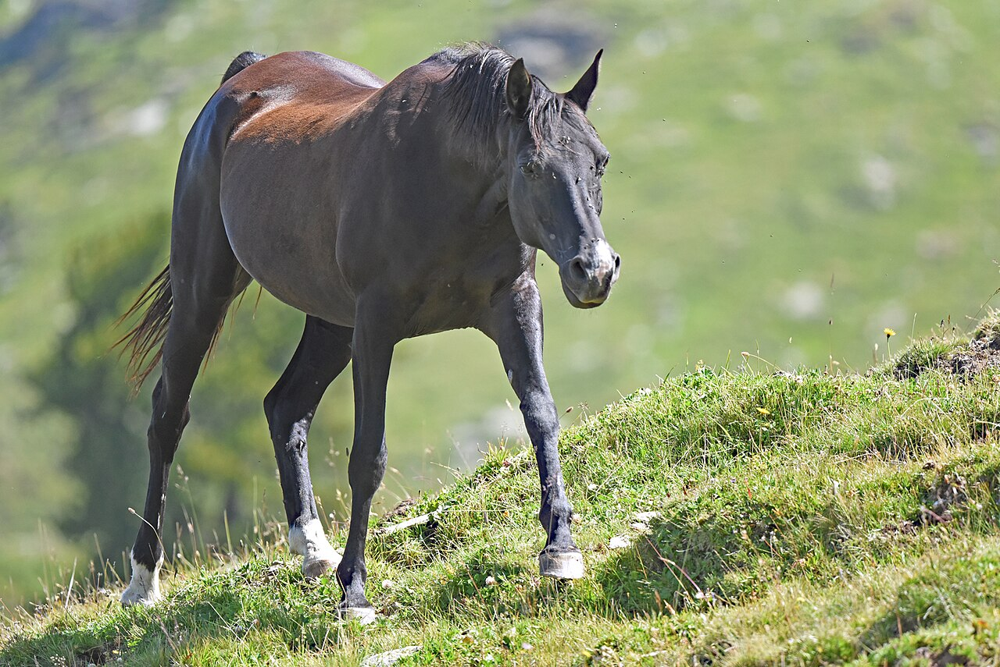

LLaVA explanation: A horse is present in the image. It has a black and brown color pattern.
------------------------------------------------------------

Rank: 2
Image: cheval.jpg
CLIP similarity: 0.2791


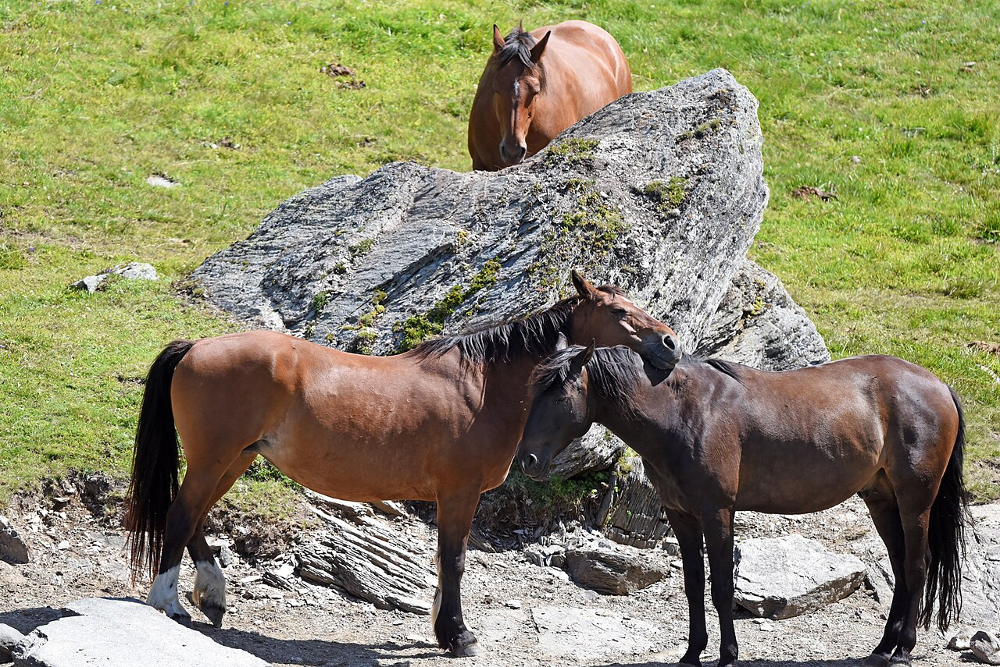

LLaVA explanation: There is a horse present in the image. It has a brown coat and is standing next to a large rock.
------------------------------------------------------------

Rank: 3
Image: Dasht1.jpg
CLIP similarity: 0.2466


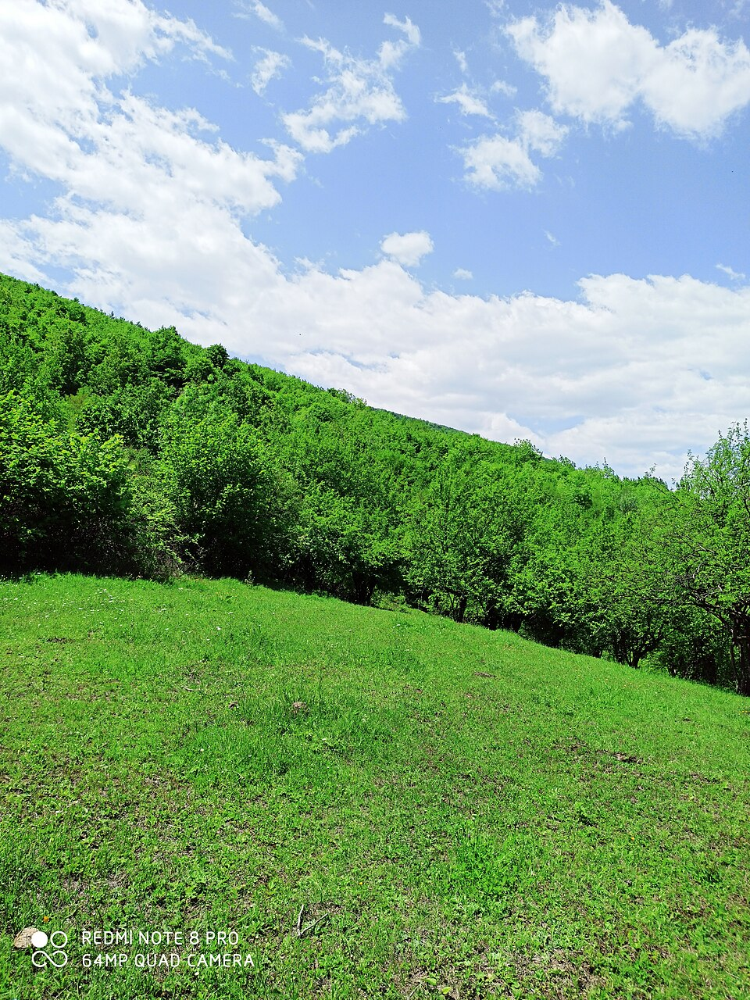

LLaVA explanation: There is a bird present in the image. It is perched on a tree branch, which is located in the middle of the scene.
------------------------------------------------------------

Rank: 4
Image: _Louie_the_Italian_Greyhound_.jpg
CLIP similarity: 0.2445


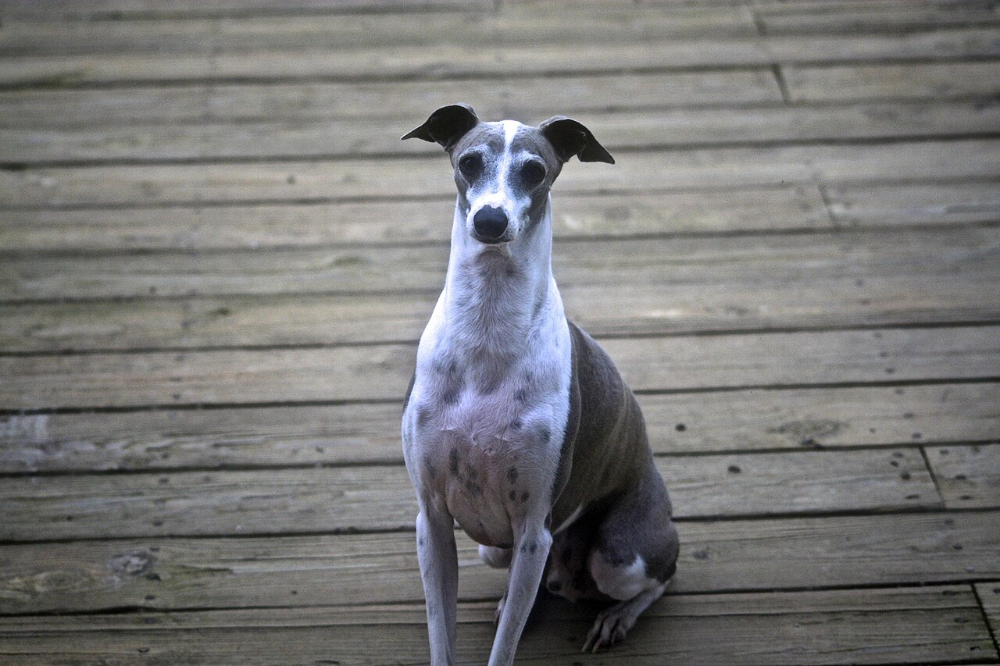

LLaVA explanation: A dog is present in the image. It has a white and gray color pattern, and it is sitting on a wooden deck.
------------------------------------------------------------

Rank: 5
Image: 18_Year_Old_Windsprite.jpg
CLIP similarity: 0.2249


In [ ]:
#################  TESTING THE ASSISTANT


results = multimodal_image_assistant(
    search_query="a photo of a horse",
    question="What animal is present in the image? Describe its appearance.",top_k=5)


### Mini-Project: Text-Based Image Retrieval and Visual Question Answering

The mini-project combines CLIP and LLaVA in a simple multimodal pipeline. Given the text query “a photo of a horse”, CLIP retrieves the five most similar images from the image dataset using image-text similarity scores. The highest-ranked image is `horse.jpg`, with a similarity score of 0.3007, followed by `cheval.jpg`, with a score of 0.2791.

LLaVA then generates a natural-language explanation for each retrieved image. Although it correctly identifies a horse in some cases, it may misinterpret other images or provide inaccurate descriptions. This demonstrates that retrieving a relevant image and correctly interpreting its content are two different tasks. The results highlight the complementary roles of CLIP and LLaVA, as well as the importance of visually checking generated answers.

## Conclusion

**This lab explored image classification, text-based image retrieval, and visual question answering using CLIP and LLaVA. CLIP achieved 100% accuracy on the tested 10-image classification task and successfully identified the most relevant image by comparing image and text embeddings. LLaVA generated natural-language descriptions and answered questions about image content, achieving 84% accuracy in the manual evaluation of 25 questions. However, the hallucination experiment showed that LLaVA can generate convincing but incorrect details when an object is absent from the image. The mini-project combines CLIP retrieval with LLaVA explanations to create a simple multimodal assistant. Overall, the results demonstrate the complementary strengths of the two models and the importance of verifying generated answers against the actual visual evidence.**